In [2]:
#load the dataset
import pandas as pd

df=pd.read_csv("/content/train_loan.csv")
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [3]:

df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
#handling missing value
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [6]:
# Fill categorical columns with mode
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Married'] = df['Married'].fillna(df['Married'].mode()[0])
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].mode()[0])
df['Self_Employed'] = df['Self_Employed'].fillna(df['Self_Employed'].mode()[0])
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mode()[0])
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

# Fill LoanAmount with median
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

# Check missing values again
print(df.isna().sum())

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


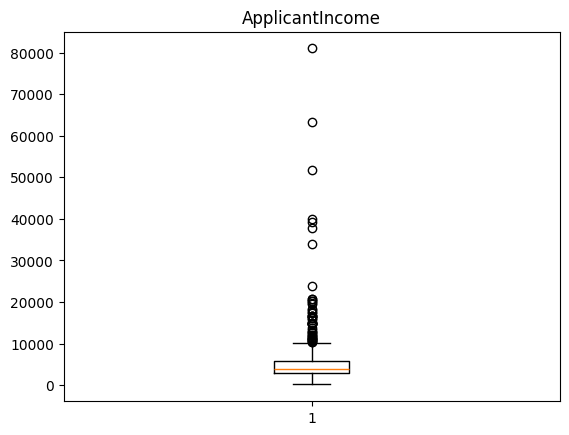

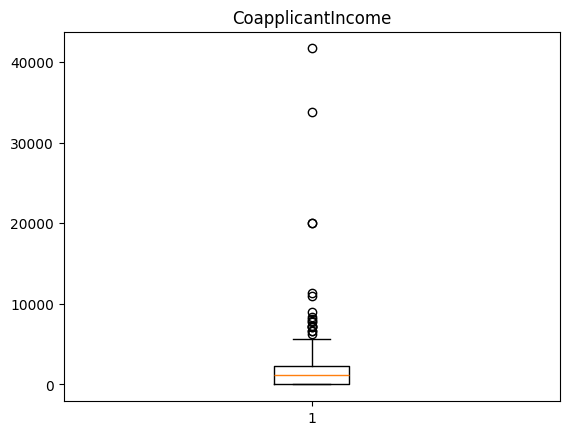

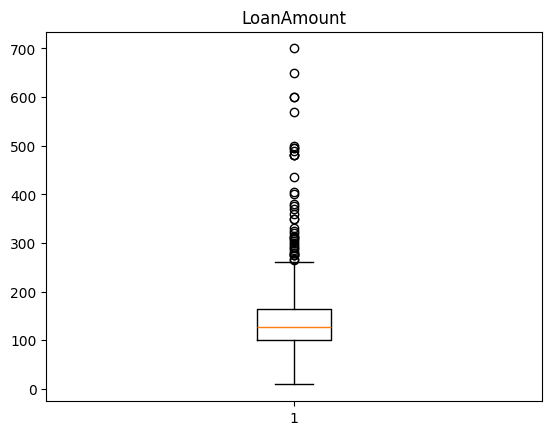

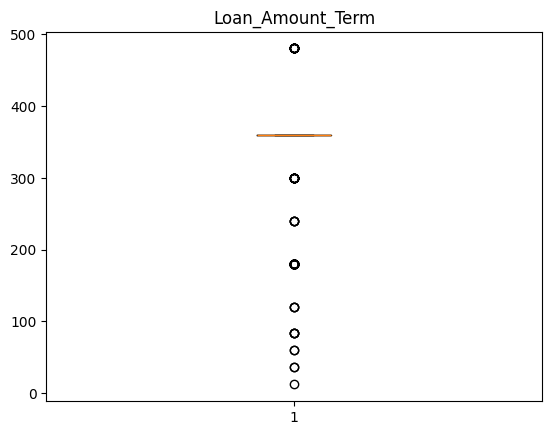

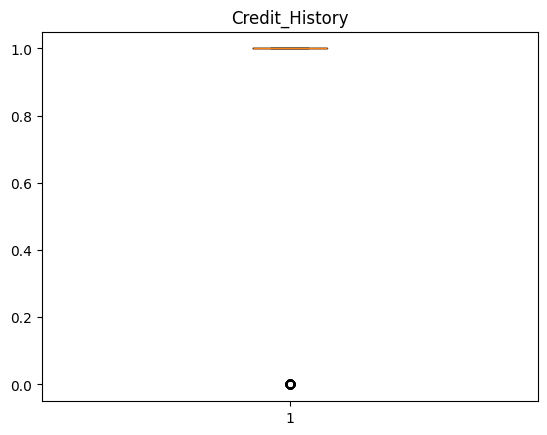

In [7]:
#. Outlier detection
import matplotlib.pyplot as plt
for i in df.select_dtypes("number").columns:
  plt.title(i)
  plt.boxplot(df[i])
  plt.show()



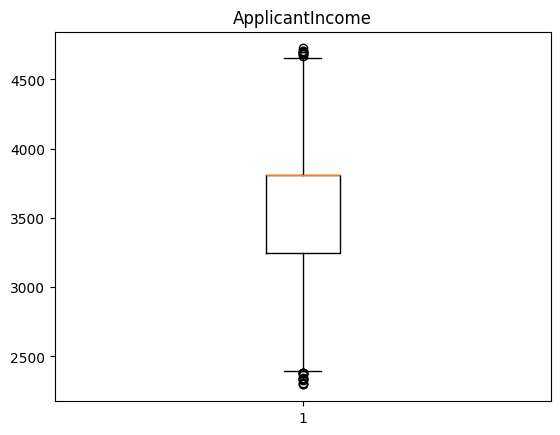

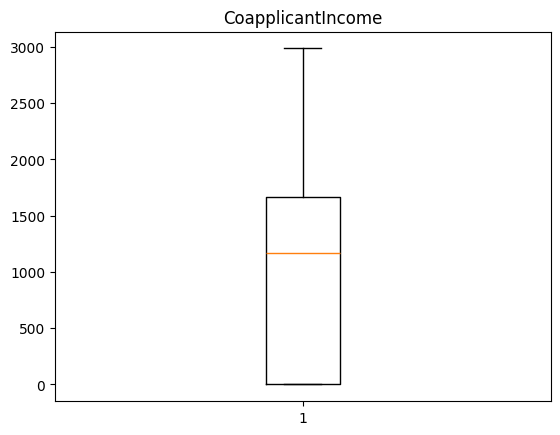

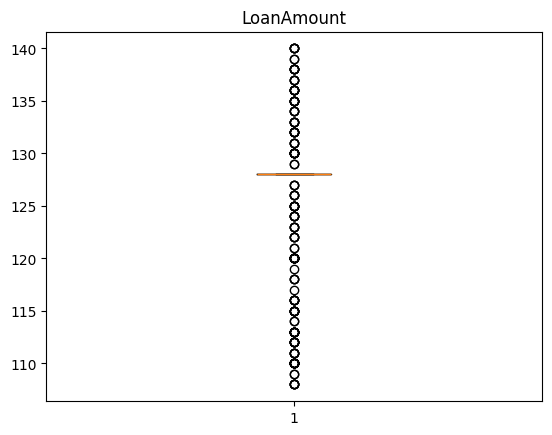

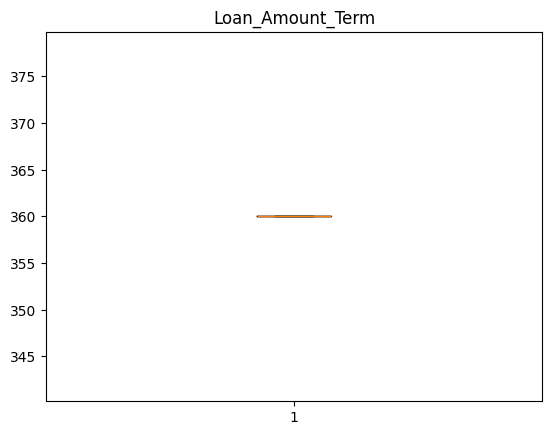

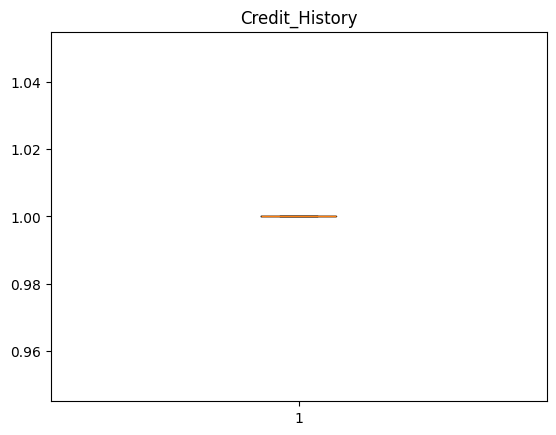

In [11]:
import matplotlib.pyplot as plt

# Detect and handle outliers
for i in df.select_dtypes("number").columns:

    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5* IQR
    upper_limit = Q3 + 1.5* IQR

    median = df[i].median()

    df.loc[(df[i] < lower_limit) | (df[i] > upper_limit), i] = median

# Display boxplots after handling outliers
for i in df.select_dtypes("number").columns:
    plt.title(i)
    plt.boxplot(df[i].dropna())
    plt.show()

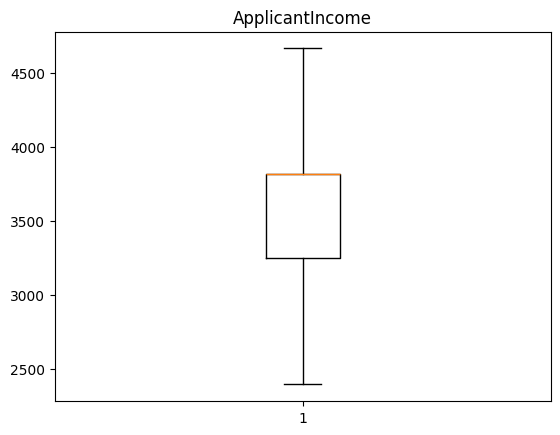

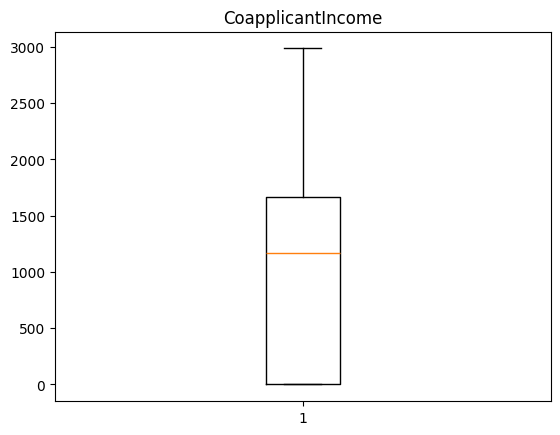

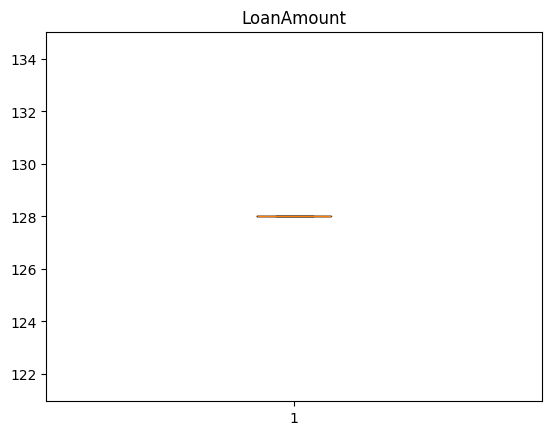

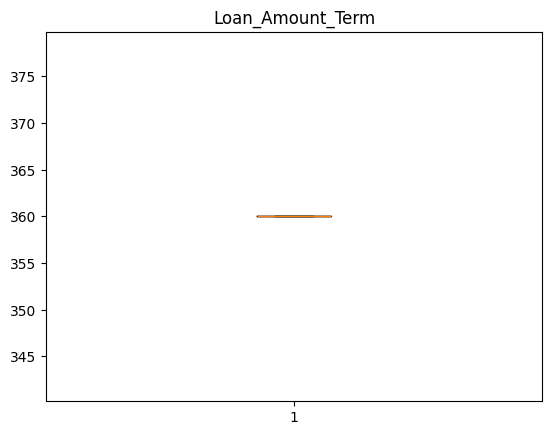

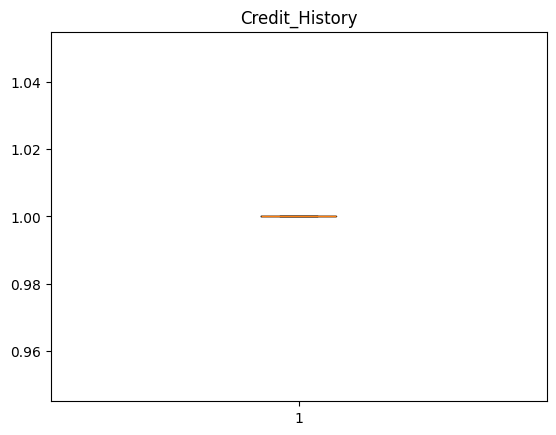

In [13]:
#outlier handling using capping
for i in df.select_dtypes("number").columns:

    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[i] = df[i].clip(lower=lower_limit, upper=upper_limit)
for i in df.select_dtypes("number").columns:
    plt.title(i)
    plt.boxplot(df[i].dropna())
    plt.show()

In [14]:
#encoding
# One-hot encoding for categorical columns
df = pd.get_dummies(
    df,
    columns=['Gender', 'Married', 'Dependents', 'Education',
             'Self_Employed', 'Property_Area'],
    drop_first=True,
    dtype=int
)


df['Loan_Status'] = df['Loan_Status'].map({'N': 0, 'Y': 1})

# Display the encoded dataset
print(df.head())

# Check data types
print(df.dtypes)

    Loan_ID  ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0  LP001002          3812.25                0.0       128.0             360.0   
1  LP001003          4583.00             1508.0       128.0             360.0   
2  LP001005          3000.00                0.0       128.0             360.0   
3  LP001006          2583.00             2358.0       128.0             360.0   
4  LP001008          3812.25                0.0       128.0             360.0   

   Credit_History  Loan_Status  Gender_Male  Married_Yes  Dependents_1  \
0             1.0            1            1            0             0   
1             1.0            0            1            1             1   
2             1.0            1            1            1             0   
3             1.0            1            1            1             0   
4             1.0            1            1            0             0   

   Dependents_2  Dependents_3+  Education_Not Graduate  Self_Employe

In [15]:
from sklearn.preprocessing import StandardScaler

# Select numerical columns for scaling
cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
        'Loan_Amount_Term']

# Apply StandardScaler
scaler = StandardScaler()
df[cols] = scaler.fit_transform(df[cols])

# Display the scaled data
print(df.head())

    Loan_ID  ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0  LP001002         0.432721          -0.986682         0.0               0.0   
1  LP001003         1.877104           0.650895         0.0               0.0   
2  LP001005        -1.089433          -0.986682         0.0               0.0   
3  LP001006        -1.870890           1.573933         0.0               0.0   
4  LP001008         0.432721          -0.986682         0.0               0.0   

   Credit_History  Loan_Status  Gender_Male  Married_Yes  Dependents_1  \
0             1.0            1            1            0             0   
1             1.0            0            1            1             1   
2             1.0            1            1            1             0   
3             1.0            1            1            1             0   
4             1.0            1            1            0             0   

   Dependents_2  Dependents_3+  Education_Not Graduate  Self_Employe